In [2]:
cd "C:\Users\Lenovo\Desktop\github projects\telcos customer churn"

C:\Users\Lenovo\Desktop\github projects\telcos customer churn


In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 

In [ ]:
## lets import all  reports and compare 

In [7]:
baseline_ml=pd.read_csv("reports/master_model_report.csv")

baseline_ann=pd.read_csv("reports/ann_model_report.csv")

tuned_catboost=pd.read_csv("reports/hyperparameter_tuning_report.csv")

tuned_ann=pd.read_csv("reports/ann_tuning_report.csv")

In [10]:
print("Baseline ML:")
display(baseline_ml)

print("\nBaseline ANN:")
display(baseline_ann)

print("\nTuned CatBoost:")
display(tuned_catboost)

print("\nTuned ANN:")
display(tuned_ann)

Baseline ML:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time (Seconds),AUC ROC RABK,Accuracy_Rank,ROC AUC Rank,Recall Rank
0,Gradient Boosting,0.7779,0.5738,0.6337,0.6023,0.8430,7.124,1.0,3.0,1,4
1,Logistic Regression,0.7459,0.5138,0.7941,0.6239,0.8402,0.173,2.0,5.0,2,1
2,CatBoost,0.7864,0.6052,0.5615,0.5825,0.8369,15.825,3.0,1.0,3,6
3,LightGBM,0.7857,0.5957,0.5989,0.5973,0.8358,0.481,4.0,2.0,4,5
4,ANN,0.7587,0.5320,0.7567,0.6247,0.8245,76.330,NaN,NaN,5,2
5,Random Forest,0.7779,0.5874,0.5481,0.5671,0.8214,5.991,5.0,3.0,6,7
6,XGBoost,0.7644,0.5603,0.5214,0.5402,0.8098,0.692,6.0,4.0,7,9
7,KNN,0.6891,0.4456,0.7005,0.5447,0.7623,0.014,7.0,7.0,8,3
8,Decision Tree,0.7147,0.4668,0.5267,0.4950,0.6544,0.252,8.0,6.0,9,8



Baseline ANN:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time (Seconds)
0,ANN,0.7587,0.532,0.7567,0.6247,0.8245,76.33



Tuned CatBoost:


,Model1,Accuracy,precision,recall,f1_score,roc_auc,CV ROC AUC,Tuning Time (Seconds),Best Parameters,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,Catboost Tuned,0.78,0.5874,0.5749,0.5811,0.8258,0.9409,215.5,"{'random_strength': 2, 'learning_rate': 0.1, '...",NaN,NaN,NaN,NaN,NaN,NaN,NaN



Tuned ANN:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Validation ROC AUC,Tuning Time,units_1,units_2,dropout_1,dropout_2,learning_rate
0,ANN Tuned,0.773598,0.558887,0.697861,0.62069,0.823088,0.908151,276.951706,192,50,0.3,0.1,0.001


In [16]:
# extract catboost now from base line moded 
catboost_baseline=baseline_ml[baseline_ml["Model"]=="CatBoost"].copy()

## 1. catboost baseline

In [19]:
print("catboost_baseline:")
display(catboost_baseline)

catboost_baseline:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time (Seconds),AUC ROC RABK,Accuracy_Rank,ROC AUC Rank,Recall Rank
2,CatBoost,0.7864,0.6052,0.5615,0.5825,0.8369,15.825,3.0,1.0,3,6


In [29]:
catboost_baseline_model=catboost_baseline[["Model","Accuracy","Precision","Recall","F1 Score","ROC AUC"]]
catboost_baseline_model

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,CatBoost,0.7864,0.6052,0.5615,0.5825,0.8369


## 2. Catboost Tuned

In [40]:
# stardaridze tuned 
tuned_catboost=tuned_catboost.rename(columns={"Model1":"Model","Accuracy":"Accuracy","precision":"Precision","recall":"Recall",
                               "f1_score":"F1 Score","roc_auc":"ROC AUC"})

tuned_catboost_result= tuned_catboost[["Model","Accuracy","Precision","Recall","F1 Score","ROC AUC"]]
tuned_catboost_result

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Catboost Tuned,0.78,0.5874,0.5749,0.5811,0.8258


## 3. Ann Base line 

In [41]:
ann_baseline_comparision= baseline_ann[["Model","Accuracy","Precision","Recall","F1 Score","ROC AUC"]]
ann_baseline_comparision

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,ANN,0.7587,0.532,0.7567,0.6247,0.8245


## 4. ANN Tuned 

In [42]:
tuned_ann_comparision=tuned_ann[["Model","Accuracy","Precision","Recall","F1 Score","ROC AUC"]]
tuned_ann_comparision

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,ANN Tuned,0.773598,0.558887,0.697861,0.62069,0.823088


In [48]:
final_comparison=pd.concat([catboost_baseline_model,tuned_catboost_result,ann_baseline_comparision,tuned_ann_comparision],axis=0)
final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,CatBoost,0.786400,0.605200,0.561500,0.58250,0.836900
0,Catboost Tuned,0.780000,0.587400,0.574900,0.58110,0.825800
0,ANN,0.758700,0.532000,0.756700,0.62470,0.824500
0,ANN Tuned,0.773598,0.558887,0.697861,0.62069,0.823088


In [50]:
final_comparson = final_comparison.sort_values(by="ROC AUC",ascending=False).reset_index(drop=True)
final_comparson

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,CatBoost,0.786400,0.605200,0.561500,0.58250,0.836900
1,Catboost Tuned,0.780000,0.587400,0.574900,0.58110,0.825800
2,ANN,0.758700,0.532000,0.756700,0.62470,0.824500
3,ANN Tuned,0.773598,0.558887,0.697861,0.62069,0.823088


In [54]:
final_comparson.to_csv("reports/final_model_comparison.csv",index=False)

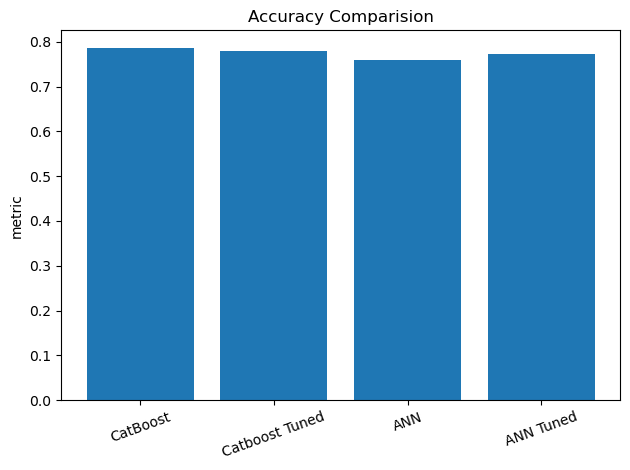

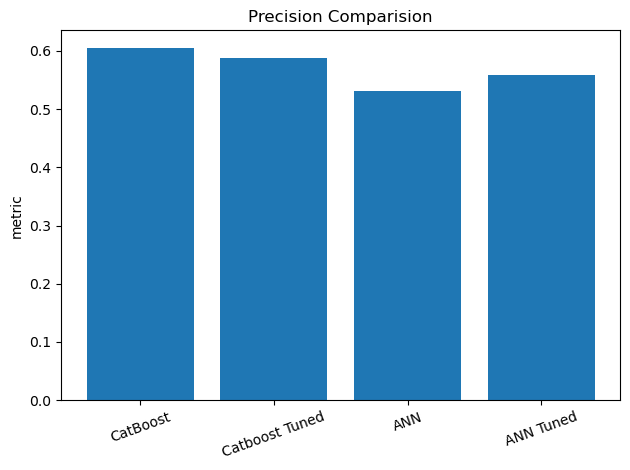

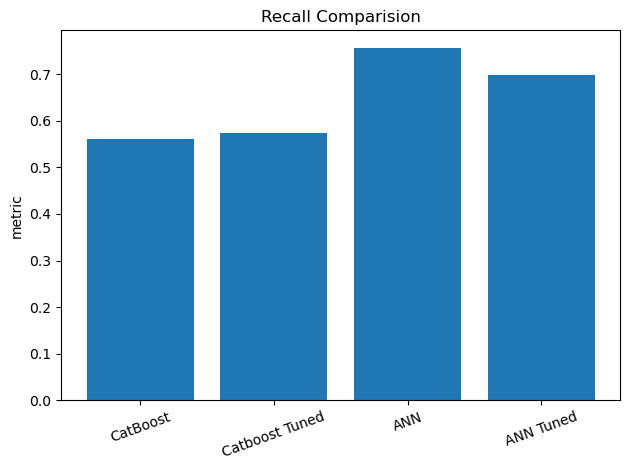

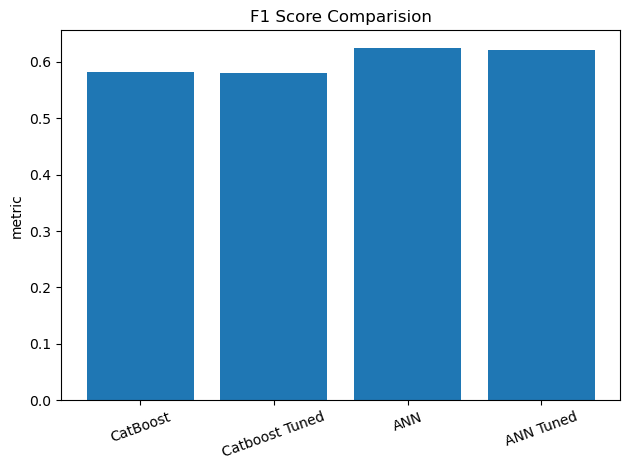

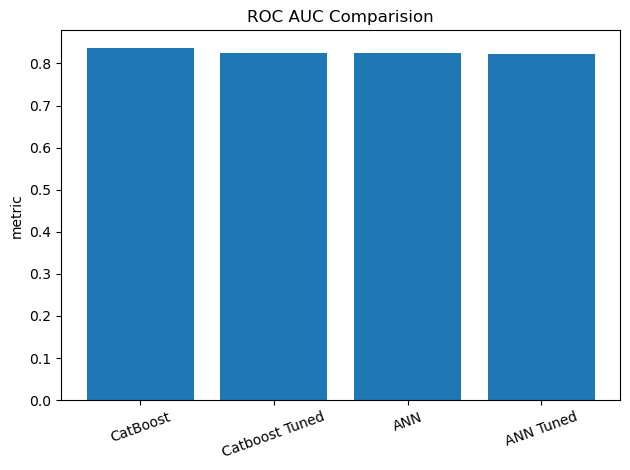

In [61]:
## final comparision 

metric=["Accuracy","Precision","Recall","F1 Score","ROC AUC"]

for metrics in metric:
    plt.bar(final_comparson["Model"],final_comparson[metrics])
    plt.title(f"{metrics} Comparision")
    plt.ylabel("metric")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()